# Hotel Booking Demand - Data Analysis & Preprocessing

**VoidMain Technologies AI Internship - Task 2**

This notebook is the walkthrough of the whole preprocessing project. All logic lives in `src/`; the notebook calls those functions and explains the results, so the notebook and `python main.py` always agree.

**Dataset:** Hotel booking demand (Antonio, Almeida & Nunes, 2019, *Data in Brief*) - real bookings from a resort hotel and a city hotel in Portugal, 2015-2017.  
**Target (context only):** `is_canceled`

## 0. Setup

In [1]:
import sys
from pathlib import Path

# Make the project root importable when running from notebooks/.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from IPython.display import Image, display

from src import config
from src.download_data import ensure_raw_data
from src.load_data import column_overview, data_quality_snapshot, load_raw_data, missing_summary

config.setup_logging()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)


def show(name: str) -> None:
    """Display a saved figure from reports/figures/."""
    display(Image(filename=str(config.FIGURES_DIR / f"{name}.png"), width=900))

## 1. Data understanding

### 1.1 Load the raw data
`ensure_raw_data()` downloads the CSV if it isn't there yet. `load_raw_data()` reads it with `na_values=['NULL']`, because this mirror stores missing `agent` / `company` / `country` values as the text `"NULL"`.

In [2]:
df = load_raw_data(ensure_raw_data())
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

13:23:18 | INFO    | src.download_data  | Raw data found at data\raw\hotel_bookings.csv - skipping download


13:23:18 | INFO    | src.load_data      | Loaded 119,390 rows x 32 columns from hotel_bookings.csv


Shape: 119,390 rows x 32 columns


### 1.2 First rows

In [3]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### 1.3 Data types and memory (`info`)

In [4]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

### 1.4 Column overview
One row per column: type, missing count/%, number of unique values and an example.

In [5]:
column_overview(df)

,dtype,non_null,missing,missing_pct,n_unique,example
hotel,str,119390,0,0.00,2,Resort Hotel
is_canceled,int64,119390,0,0.00,2,0
lead_time,int64,119390,0,0.00,479,342
arrival_date_year,int64,119390,0,0.00,3,2015
arrival_date_month,str,119390,0,0.00,12,July
arrival_date_week_number,int64,119390,0,0.00,53,27
arrival_date_day_of_month,int64,119390,0,0.00,31,1
stays_in_weekend_nights,int64,119390,0,0.00,17,0
stays_in_week_nights,int64,119390,0,0.00,35,0
adults,int64,119390,0,0.00,14,2


### 1.5 Numeric summary (`describe`)

In [6]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


### 1.6 Categorical summary

In [7]:
df.select_dtypes(exclude="number").describe().T

,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


### 1.7 Missing values

In [8]:
missing_summary(df)

,missing,missing_pct
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


13:23:19 | WARNING | matplotlib.font_manager | findfont: Failed to find font weight 600 for DejaVu Sans, now using 700.


13:23:19 | INFO    | src.visualize      | Saved figure 01_missing_values.png


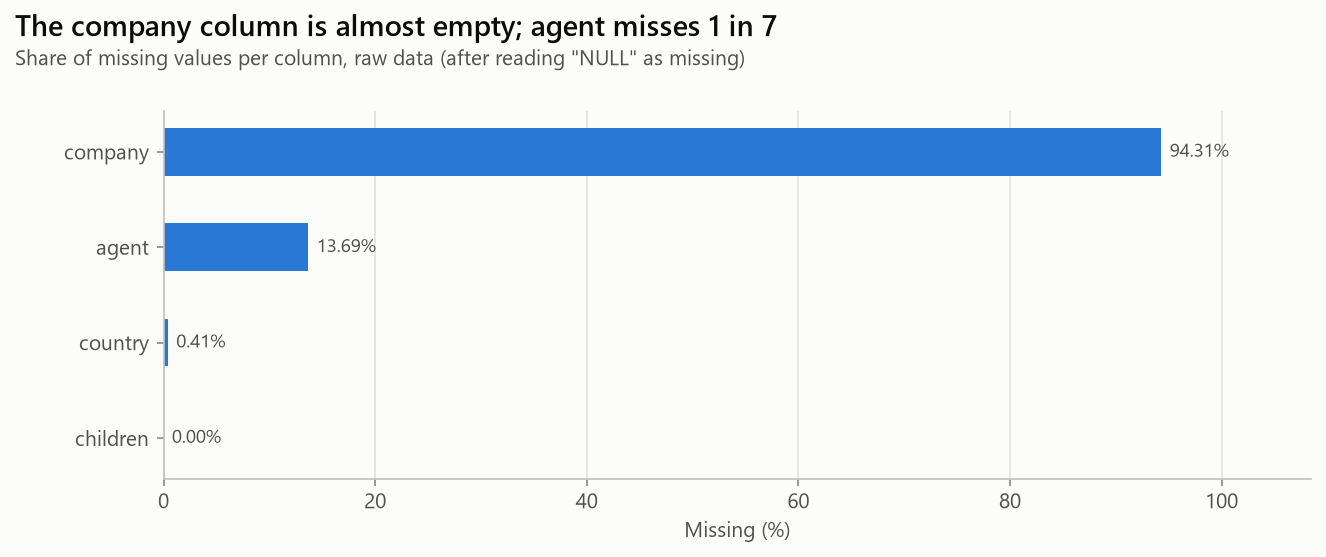

In [9]:
from src.visualize import plot_missing_values, save_figure

save_figure(plot_missing_values(df), "01_missing_values")
show("01_missing_values")

### 1.8 Target balance

In [10]:
target_counts = df[config.TARGET].value_counts().rename({0: "not canceled", 1: "canceled"})
pd.DataFrame({"count": target_counts, "pct": (target_counts / len(df) * 100).round(2)})

,count,pct
is_canceled,,
not canceled,75166,62.96
canceled,44224,37.04


### 1.9 Cancellation rate by hotel

In [11]:
df.groupby("hotel")[config.TARGET].agg(bookings="size", cancel_rate="mean").assign(
    cancel_rate=lambda t: (t["cancel_rate"] * 100).round(2)
)

,bookings,cancel_rate
hotel,,
City Hotel,79330,41.73
Resort Hotel,40060,27.76


### 1.10 Data-quality snapshot
Counting the known problems *before* fixing anything in Stage 2.

In [12]:
pd.Series(data_quality_snapshot(df), name="value", dtype=object).to_frame()

,value
rows,119390
duplicate_rows,31994
rows_with_any_missing,119173
zero_guest_bookings,180
negative_adr,1
zero_adr,1959
adr_max,5400.0
cancellation_rate_pct,37.04


### 1.11 Closer look at specific columns

In [13]:
print('Hidden "Undefined" categories:')
for col in ["meal", "market_segment", "distribution_channel"]:
    print(f"  {col:22s}", (df[col] == "Undefined").sum())

print("\nADR extremes:")
print(df["adr"].describe(percentiles=[0.01, 0.5, 0.99]).round(2).to_string())

print("\nTop 10 countries (of", df["country"].nunique(), "unique):")
print((df["country"].value_counts(normalize=True).head(10) * 100).round(2).to_string())

Hidden "Undefined" categories:
  meal                   1169
  market_segment         2
  distribution_channel   5

ADR extremes:
count    119390.00
mean        101.83
std          50.54
min          -6.38
1%            0.00
50%          94.58
99%         252.00
max        5400.00

Top 10 countries (of 177 unique):
country
PRT    40.87
GBR    10.20
FRA     8.76
ESP     7.21
DEU     6.13
ITA     3.17
IRL     2.84
BEL     1.97
BRA     1.87
NLD     1.77


In [14]:
print("reservation_status vs is_canceled (leakage check):")
pd.crosstab(df["reservation_status"], df[config.TARGET])

reservation_status vs is_canceled (leakage check):


is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


### 1.12 Key observations (Stage 1)

**Size & types**
- 119,390 bookings x 32 columns, 2015-2017. City Hotel = 79,330 bookings, Resort Hotel = 40,060.
- 16 int, 4 float, 12 text columns. `agent` and `company` are numeric **IDs**, not quantities -> must be treated as categories.
- `children` is float only because it has missing values; it should be an integer count.
- Arrival date is split across 4 columns (year, month name, week number, day) -> good material for feature engineering.

**Missing values** (after treating `"NULL"` as missing)
| Column | Missing | % | Likely meaning |
|---|---|---|---|
| `company` | 112,593 | 94.3% | No company involved (not a data error) |
| `agent` | 16,340 | 13.7% | Booked directly, no travel agent |
| `country` | 488 | 0.4% | Genuinely unknown |
| `children` | 4 | ~0% | Genuinely unknown |

So the large gaps are *structural* ("not applicable"), not random - which drives the Stage 2 treatment.

**Duplicates:** 31,994 fully identical rows (26.8%). The dataset has no booking ID, so some may be genuine identical group bookings - needs a reasoned decision in Stage 2.

**Invalid values / outliers**
- 180 bookings with 0 adults + 0 children + 0 babies -> invalid.
- `adr` (average daily rate): 1 negative value (-6.38), 1,959 zeros (complimentary stays exist), max 5,400 while the 99th percentile is only 252 -> extreme outlier.
- Suspicious maxima: `adults` = 55, `babies` = 10, `required_car_parking_spaces` = 8.

**Hidden missing values:** `meal` has 1,169 `"Undefined"` (per the dataset paper, Undefined = SC / no meal); `market_segment` has 2 and `distribution_channel` 5 `"Undefined"`.

**High cardinality:** `country` has 177 values, but PRT (40.9%), GBR, FRA, ESP, DEU cover ~73% -> rare countries can be grouped.

**Target:** 37.0% canceled - moderately imbalanced. City Hotel cancels much more (41.7%) than Resort (27.8%).

**Leakage confirmed:** `reservation_status` maps perfectly onto the target (Canceled/No-Show = canceled, Check-Out = not canceled), and `reservation_status_date` is recorded *after* the outcome. Both must be dropped from the model-ready output.

## 2. Cleaning

All rules live in `src/cleaning.py` (values in `src/config.py`); the full reasoning and alternatives are in `docs/decisions.md`, section 2.

**Order matters:** invalid rows -> exact duplicates -> missing values -> category fixes -> outlier capping. Duplicates are removed *before* `company` is dropped, otherwise rows that only differed by company ID would wrongly look identical.

In [15]:
from src.cleaning import before_after_summary, clean_data, save_clean_data

clean_df, step_report, adr_cap = clean_data(df)

13:23:19 | INFO    | src.cleaning       | -> Drop zero-guest bookings


13:23:19 | INFO    | src.cleaning       | Zero-guest bookings dropped: 180


13:23:20 | INFO    | src.cleaning       | -> Drop negative ADR


13:23:20 | INFO    | src.cleaning       | Negative-ADR rows dropped: 1


13:23:20 | INFO    | src.cleaning       | -> Drop implausible counts


...

13:23:21 | INFO    | src.cleaning       | meal relabelled {'Undefined': 'SC'}: 492 rows


13:23:21 | INFO    | src.cleaning       | -> Cap extreme ADR


13:23:21 | INFO    | src.cleaning       | ADR capped at 335.00: 85 rows, old max 5400.00


13:23:21 | WARNING | src.cleaning       | Leakage columns kept for EDA, dropped before modelling: ['reservation_status', 'reservation_status_date']


13:23:21 | INFO    | src.cleaning       | Cleaning done: 119,390 -> 87,208 rows (32,182 removed, 27.0%)


### 2.1 What each step did

In [16]:
step_report

,rows_before,rows_after,rows_removed,values_changed,columns
step,,,,,
Drop zero-guest bookings,119390,119210,180,0,
Drop negative ADR,119210,119209,1,0,
Drop implausible counts,119209,119188,21,0,
Drop exact duplicates,119188,87208,31980,0,
company -> has_company flag,87208,87208,0,0,"+has_company, -company"
Fill agent + has_agent flag,87208,87208,0,12128,+has_agent
Fill country 'Unknown',87208,87208,0,447,
Fill children 0,87208,87208,0,4,
meal Undefined -> SC,87208,87208,0,492,


13:23:21 | INFO    | src.visualize      | Saved figure 02_cleaning_steps.png


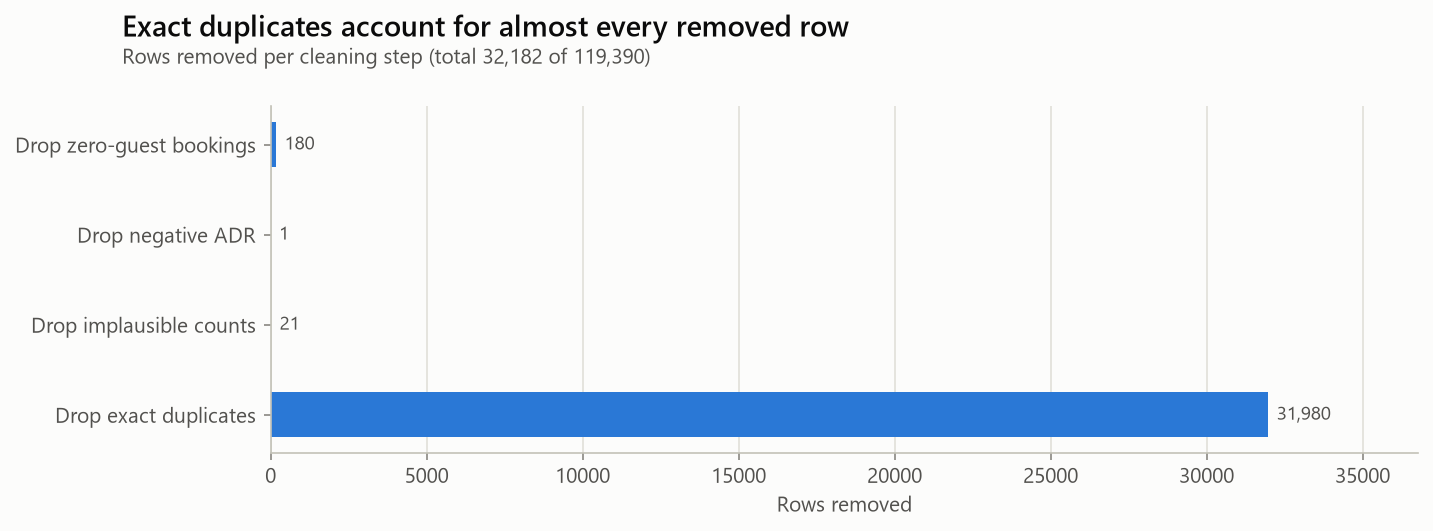

In [17]:
from src.visualize import plot_cleaning_steps

save_figure(plot_cleaning_steps(step_report), "02_cleaning_steps")
show("02_cleaning_steps")

### 2.2 Before vs after

In [18]:
before_after_summary(df, clean_df)

,before,after
rows,119390,87208
duplicate_rows,31994,4
zero_guest_bookings,180,0
negative_adr,1,0
adr_max,5400.0,335.0
missing: children,4,0
missing: country,488,0
missing: agent,16340,0
missing: company,112593,dropped
total missing cells,129425,0


### 2.3 Why the cancellation rate dropped (37.0% -> 27.5%)
The removed duplicates are not a random sample - they are mostly group blocks.

*Computed on the raw file, so it shows 31,994 duplicates; the pipeline removes 31,980 because 14 of them were already dropped as zero-guest bookings.*

13:23:22 | INFO    | src.visualize      | Saved figure 03_duplicates_profile.png


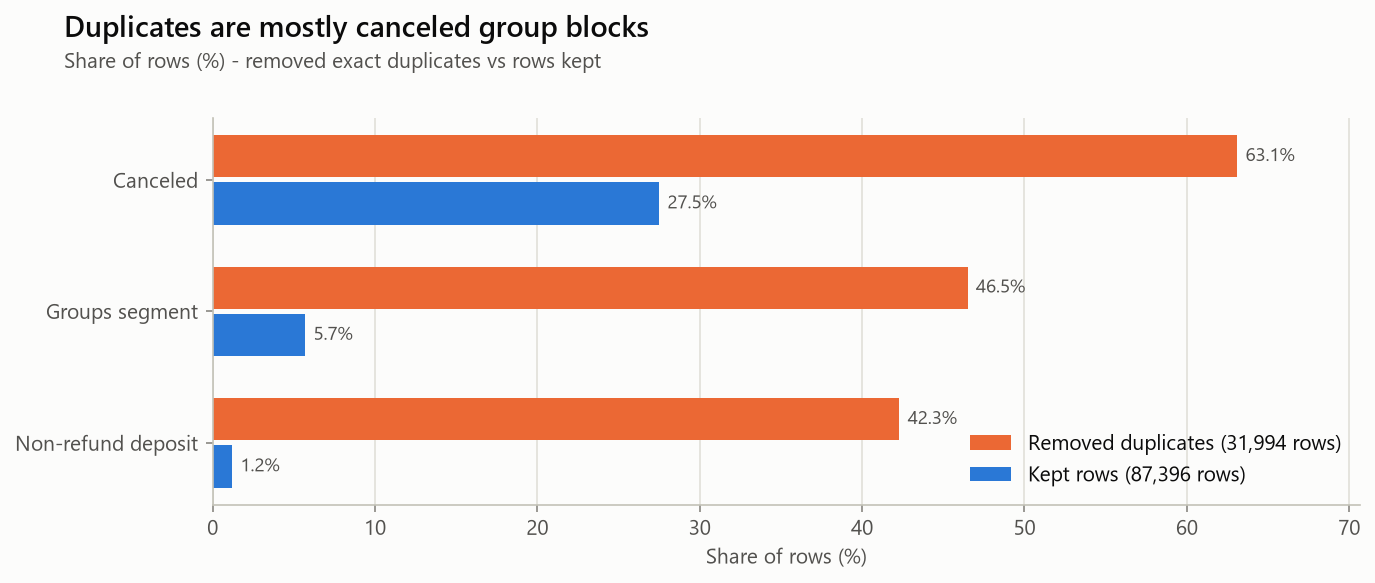

,rows,cancel_rate_pct,groups_segment_pct,non_refund_pct
Removed duplicates,31994,63.1,46.5,42.3
Kept rows,87396,27.5,5.7,1.2


In [19]:
from src import eda
from src.visualize import plot_duplicates_profile

save_figure(plot_duplicates_profile(df), "03_duplicates_profile")
show("03_duplicates_profile")
eda.duplicates_profile(df)

### 2.4 Count columns: why a gap rule instead of IQR
`adults` jumps from 4 straight to 5, 6, 10, 20 ... 55. The IQR of `adults` is 0, so an IQR rule would flag every booking with 3+ adults (6,280 rows). The gap rule removes only the 16 impossible ones.

In [20]:
df["adults"].value_counts().sort_index().to_frame("bookings").T

adults,0,1,2,3,4,5,6,10,20,26,27,40,50,55
bookings,403,23027,89680,6202,62,2,1,1,2,5,2,1,1,1


### 2.5 ADR before vs after
Zeros are kept (complimentary / day-use stays); the single negative row is dropped; values above the 99.9th percentile are capped.

13:23:22 | INFO    | src.visualize      | Saved figure 04_adr_before_after.png


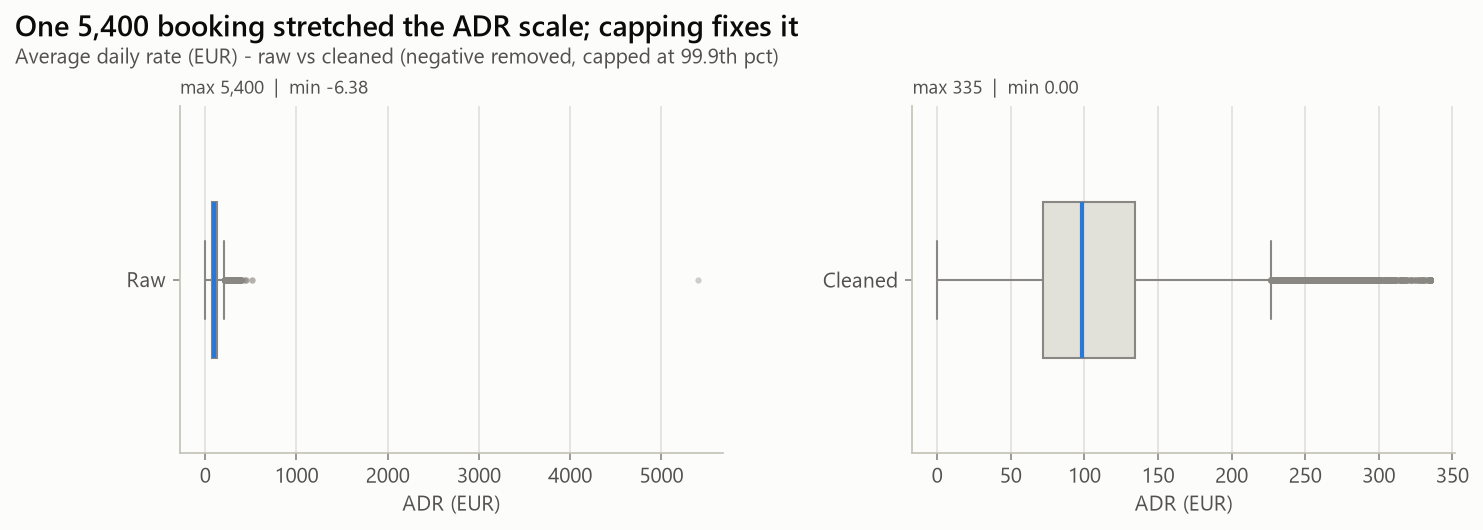

,count,mean,std,min,25%,50%,75%,max
raw,119390.0,101.83,50.54,-6.38,69.29,94.58,126.0,5400.0
clean,87208.0,106.45,51.72,0.00,72.25,98.25,134.1,335.0


In [21]:
from src.visualize import plot_adr_before_after

save_figure(plot_adr_before_after(df, clean_df), "04_adr_before_after")
show("04_adr_before_after")
pd.DataFrame({"raw": df["adr"].describe(), "clean": clean_df["adr"].describe()}).round(2).T

### 2.6 Save the cleaned data

In [22]:
save_clean_data(clean_df)
clean_df.head()

13:23:22 | INFO    | src.cleaning       | Saved cleaned data: hotel_bookings_clean.csv (87,208 rows x 33 columns)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,has_company,has_agent
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,0,0,Transient,0.0,0,0,Check-Out,2015-07-01,0,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,0,0,Transient,0.0,0,0,Check-Out,2015-07-01,0,0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,0,0,Transient,75.0,0,0,Check-Out,2015-07-02,0,0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304,0,Transient,75.0,0,0,Check-Out,2015-07-02,0,1
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240,0,Transient,98.0,0,1,Check-Out,2015-07-03,0,1


### 2.7 Key takeaways (Stage 2)

- **119,390 -> 87,208 rows** (27% removed, almost all exact duplicates); **129,425 missing cells -> 0**.
- Missing values were treated by *meaning*: no company / no agent became flags (`has_company`, `has_agent`), unknown country became `"Unknown"`, 4 missing children became 0.
- Invalid rows dropped: 180 zero-guest bookings, 1 negative ADR, 21 impossible counts (e.g. 55 adults, 10 babies).
- ADR capped at the 99.9th percentile (335), so 5,400 no longer dominates; zero prices kept.
- **Trade-off:** dropping duplicates prevents train/test leakage but removes mostly canceled group blocks, so the cancellation rate falls from 37.0% to 27.5%.
- `reservation_status` / `reservation_status_date` are still present (flagged) and get removed in feature selection.

## 3. Feature engineering

Ten new features, all computed **within a single row** (no dataset-wide statistics), so creating them before the train/test split cannot leak test information. Details: `docs/decisions.md` section 3.

| Feature | Meaning |
|---|---|
| `total_nights` | weekend + week nights |
| `total_guests` | adults + children + babies |
| `has_children` | any children or babies |
| `adr_per_person` | price per paying guest (babies stay free) |
| `stay_value` | ADR x nights - money at stake |
| `arrival_month_num`, `arrival_weekday`, `arrival_season` | from the rebuilt arrival date |
| `is_domestic` | guest from Portugal (both hotels are Portuguese) |
| `previous_cancel_ratio` | share of the guest's earlier bookings that were canceled |

In [23]:
from src.features import engineer_features

featured = engineer_features(clean_df)
featured[config.ENGINEERED_FEATURES].head()

13:23:22 | INFO    | src.features       | Engineered 10 features: ['total_nights', 'total_guests', 'has_children', 'adr_per_person', 'stay_value', 'arrival_month_num', 'arrival_weekday', 'arrival_season', 'is_domestic', 'previous_cancel_ratio']


13:23:22 | INFO    | src.features       | Shape after feature engineering: 87,208 rows x 43 columns


,total_nights,total_guests,has_children,adr_per_person,stay_value,arrival_month_num,arrival_weekday,arrival_season,is_domestic,previous_cancel_ratio
0,0,2,0,0.0,0.0,7,2,Summer,1,0.0
1,0,2,0,0.0,0.0,7,2,Summer,1,0.0
2,1,1,0,75.0,75.0,7,2,Summer,0,0.0
3,1,1,0,75.0,75.0,7,2,Summer,0,0.0
4,2,2,0,49.0,196.0,7,2,Summer,0,0.0


In [24]:
featured[config.ENGINEERED_FEATURES].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
total_nights,87208.0,NaN,NaN,NaN,3.627947,2.742704,0.0,2.0,3.0,5.0,69.0
total_guests,87208.0,NaN,NaN,NaN,2.024631,0.700423,1.0,2.0,2.0,2.0,5.0
has_children,87208.0,NaN,NaN,NaN,0.104348,0.305714,0.0,0.0,0.0,0.0,1.0
adr_per_person,87208.0,NaN,NaN,NaN,55.750333,28.345776,0.0,38.0,50.03,67.5,335.0
stay_value,87208.0,NaN,NaN,NaN,394.832783,368.307782,0.0,153.0,299.2,504.0,7590.0
arrival_month_num,87208.0,NaN,NaN,NaN,6.474486,3.096443,1.0,4.0,7.0,9.0,12.0
arrival_weekday,87208.0,NaN,NaN,NaN,2.980071,2.007015,0.0,1.0,3.0,5.0,6.0
arrival_season,87208,4,Summer,29040,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_domestic,87208.0,NaN,NaN,NaN,0.313469,0.463906,0.0,0.0,0.0,1.0,1.0
previous_cancel_ratio,87208.0,NaN,NaN,NaN,0.013743,0.11188,0.0,0.0,0.0,0.0,1.0


### 3.1 Do the new features carry signal? (cancellation rate per value)

In [25]:
pd.concat(
    {
        "has_children": eda.cancellation_rate_by(featured, "has_children"),
        "is_domestic": eda.cancellation_rate_by(featured, "is_domestic"),
        "arrival_season": eda.cancellation_rate_by(featured, "arrival_season"),
        "has_cancel_history": eda.cancellation_rate_by(
            featured.assign(has_cancel_history=featured["previous_cancel_ratio"] > 0),
            "has_cancel_history",
        ),
    }
)

bookings  cancel_rate_pct
has_children       0          78108             26.7
                   1           9100             34.3
is_domestic        0          59871             23.8
                   1          27337             35.7
arrival_season     Summer     29040             31.6
                   Spring     23730             28.1
                   Autumn     18559             23.3
                   Winter     15879             24.1
has_cancel_history 0          85527             26.7
                   1           1681             68.0

**Rejected feature:** `room_type_changed` (reserved != assigned room). Rooms are reassigned at check-in, which canceled bookings never reach - changed-room bookings cancel only 4.7% vs 31.5%. It would leak the outcome, so it was not created.

## 4. Exploratory data analysis

All numbers come from `src/eda.py` (the web app uses the same functions). Rates are shown instead of counts, with the overall cancellation rate (27.5%) as a reference line.

In [26]:
from src.visualize import generate_eda_figures

figure_paths = generate_eda_figures(df, clean_df, featured, step_report)
[p.name for p in figure_paths]

13:23:23 | INFO    | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


13:23:23 | INFO    | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


13:23:23 | INFO    | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


13:23:23 | INFO    | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


13:23:23 | INFO    | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


...

13:23:23 | INFO    | src.visualize      | Saved figure 07_monthly_adr.png


13:23:24 | INFO    | src.visualize      | Saved figure 08_cancel_by_deposit_and_segment.png


13:23:24 | INFO    | src.visualize      | Saved figure 09_top_countries.png


13:23:24 | INFO    | src.visualize      | Saved figure 10_cancel_by_special_requests.png


['01_missing_values.png',
 '02_cleaning_steps.png',
 '03_duplicates_profile.png',
 '04_adr_before_after.png',
 '05_cancel_by_lead_time.png',
 '06_monthly_cancellation.png',
 '07_monthly_adr.png',
 '08_cancel_by_deposit_and_segment.png',
 '09_top_countries.png',
 '10_cancel_by_special_requests.png']

### 4.1 Lead time is the clearest driver
Bookings made within a week cancel 8.4% of the time; bookings made over a year ahead cancel 40.8%. More time = more chances for plans to change.

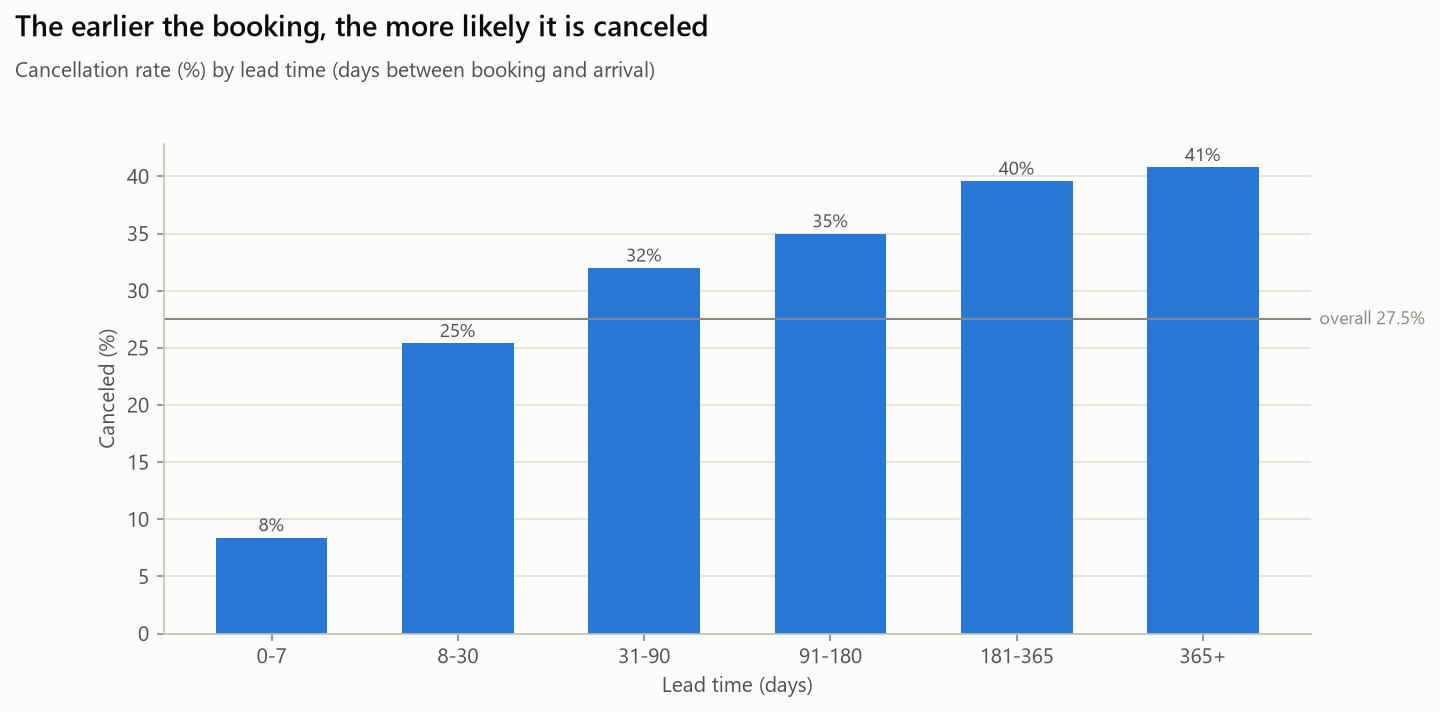

In [27]:
show("05_cancel_by_lead_time")

### 4.2 Seasonality: Resort is seasonal, City is not
Resort cancellations rise from ~14% in January to ~32% in August, together with prices (average ADR 49 -> 187 EUR). City cancellations stay high all year (25-34%).

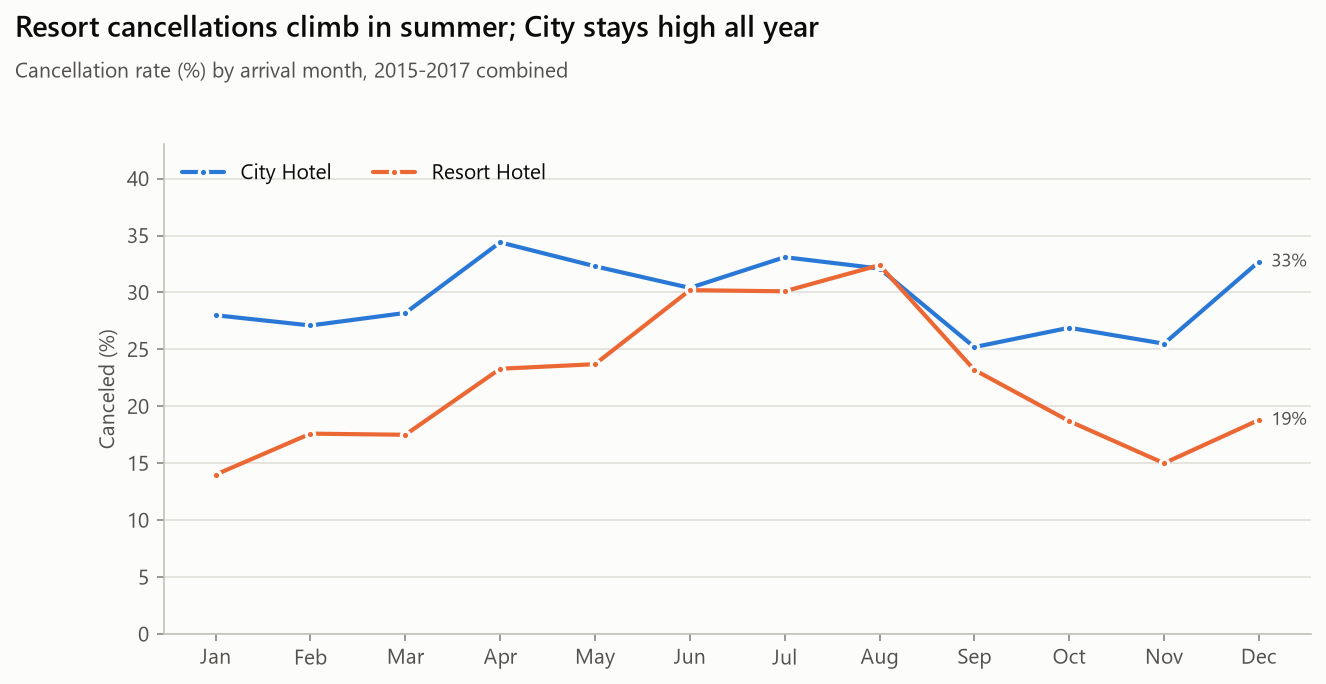

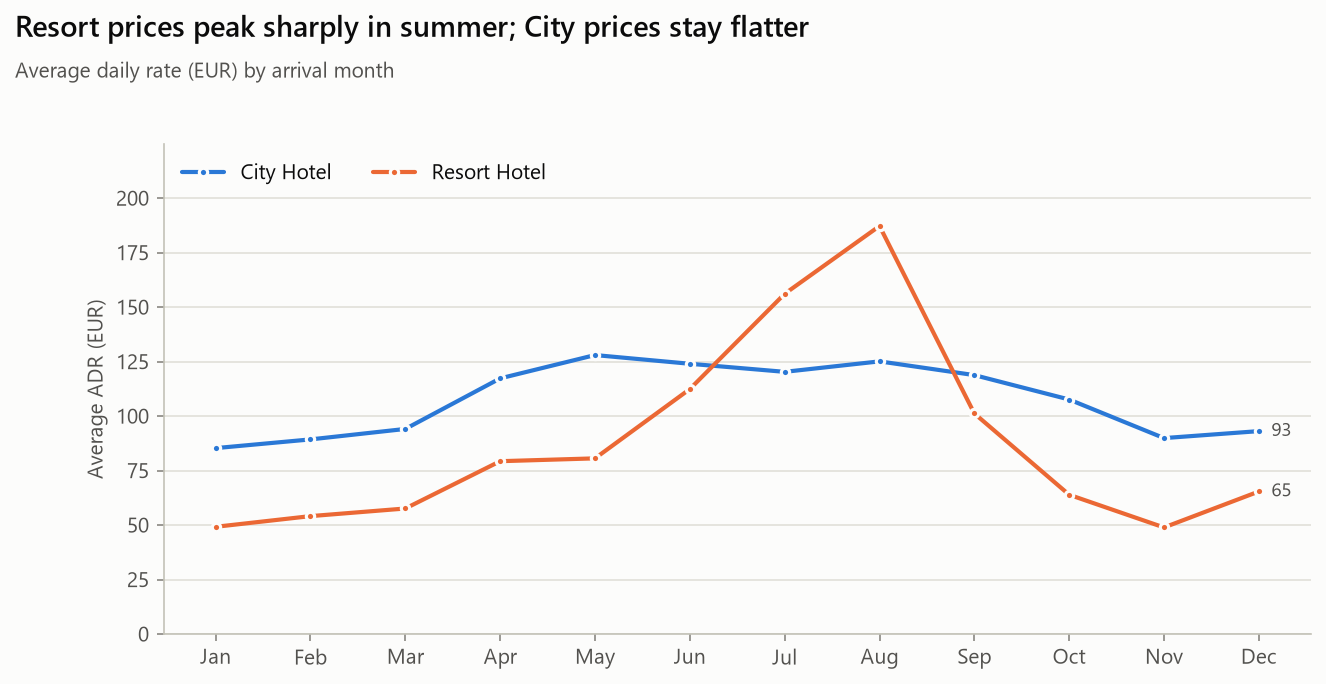

In [28]:
show("06_monthly_cancellation")
show("07_monthly_adr")

### 4.3 Deposit type and market segment
Non-refundable deposits cancel 94.7% of the time - counter-intuitive, but 63% of them are Groups and 28% Offline TA/TO with a median lead time of 188 days: large allotments booked far ahead and released later. Online travel agents cancel the most among segments (35.4%).

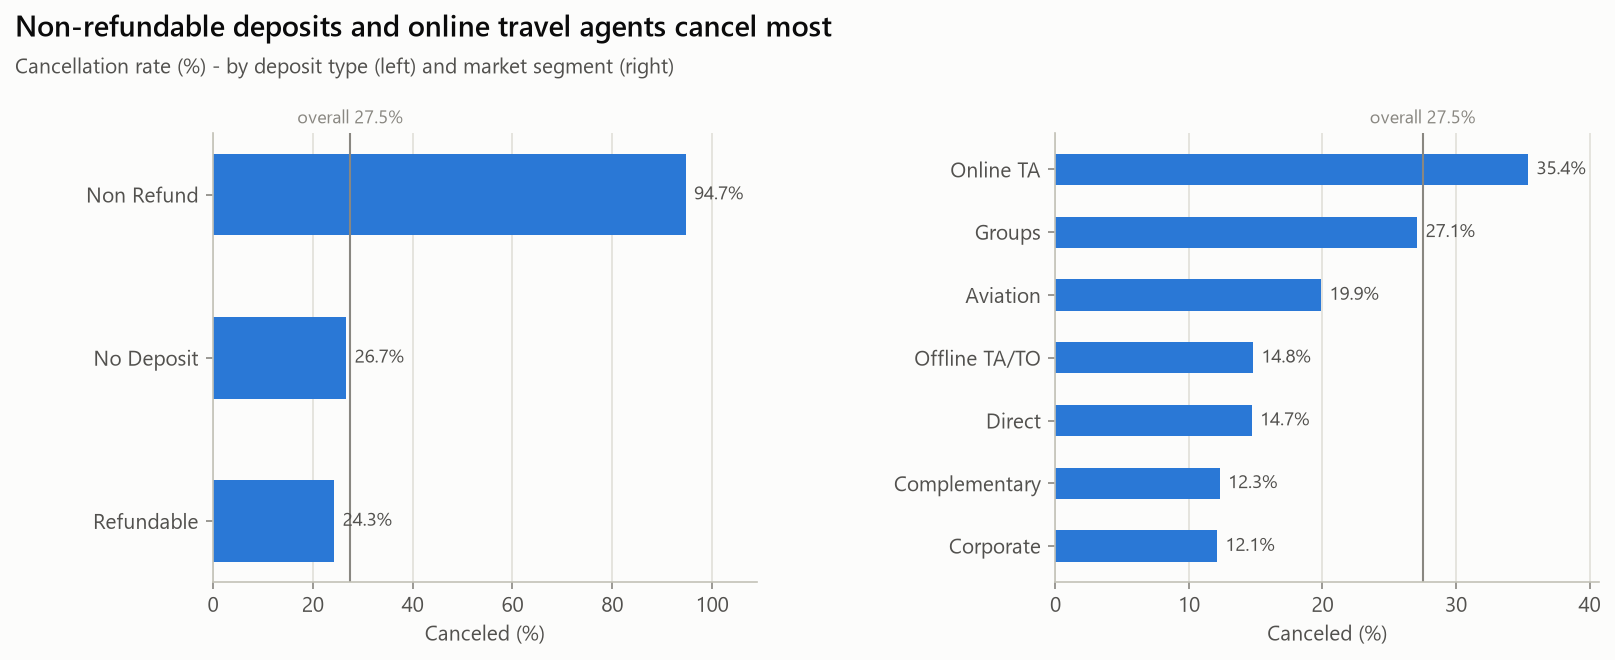

In [29]:
show("08_cancel_by_deposit_and_segment")

### 4.4 Country
Portugal is 31% of bookings and cancels 35.7%, well above the 18-26% of the next big markets (GBR, FRA, ESP, DEU). This is why `is_domestic` was engineered.

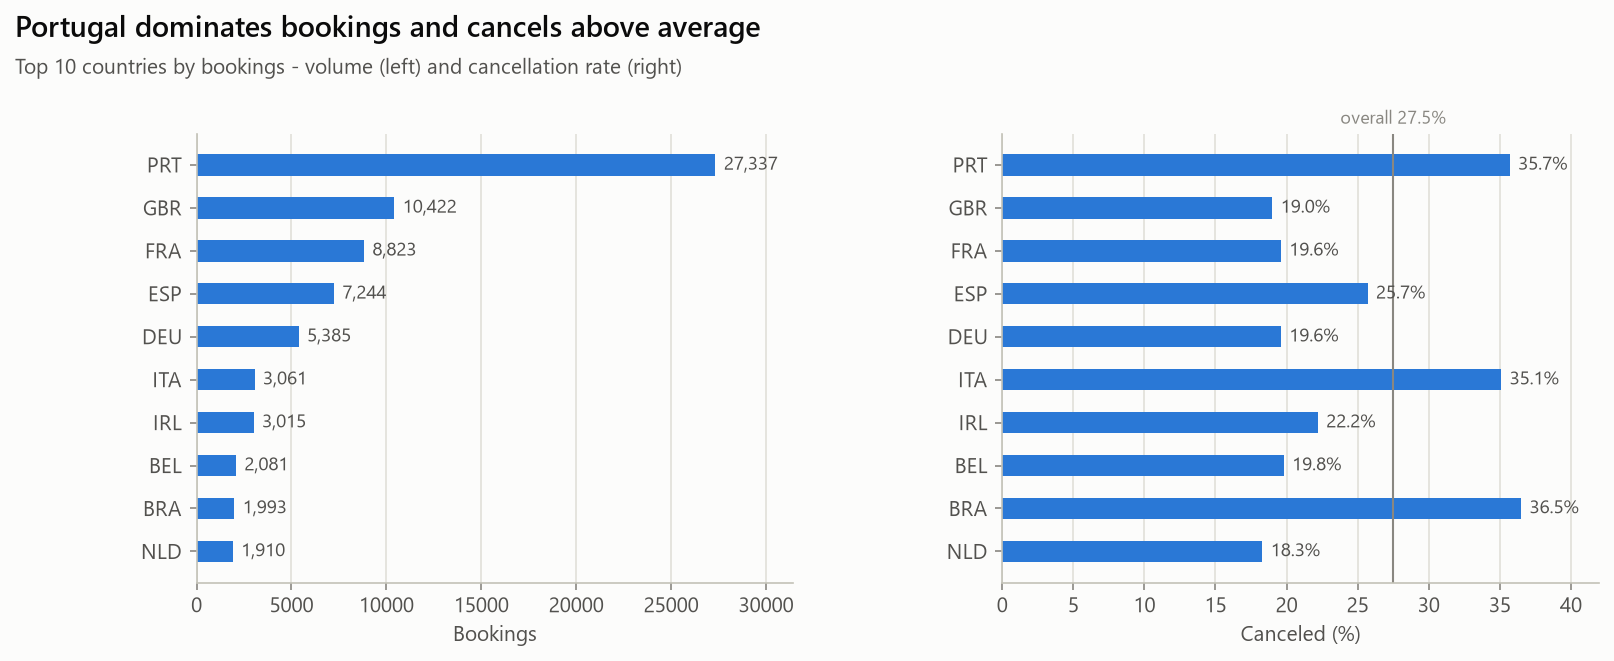

In [30]:
show("09_top_countries")

### 4.5 Special requests signal commitment
33% of bookings with no special requests are canceled vs 6% with five. A guest who asks for a quiet room or a crib is planning to come.

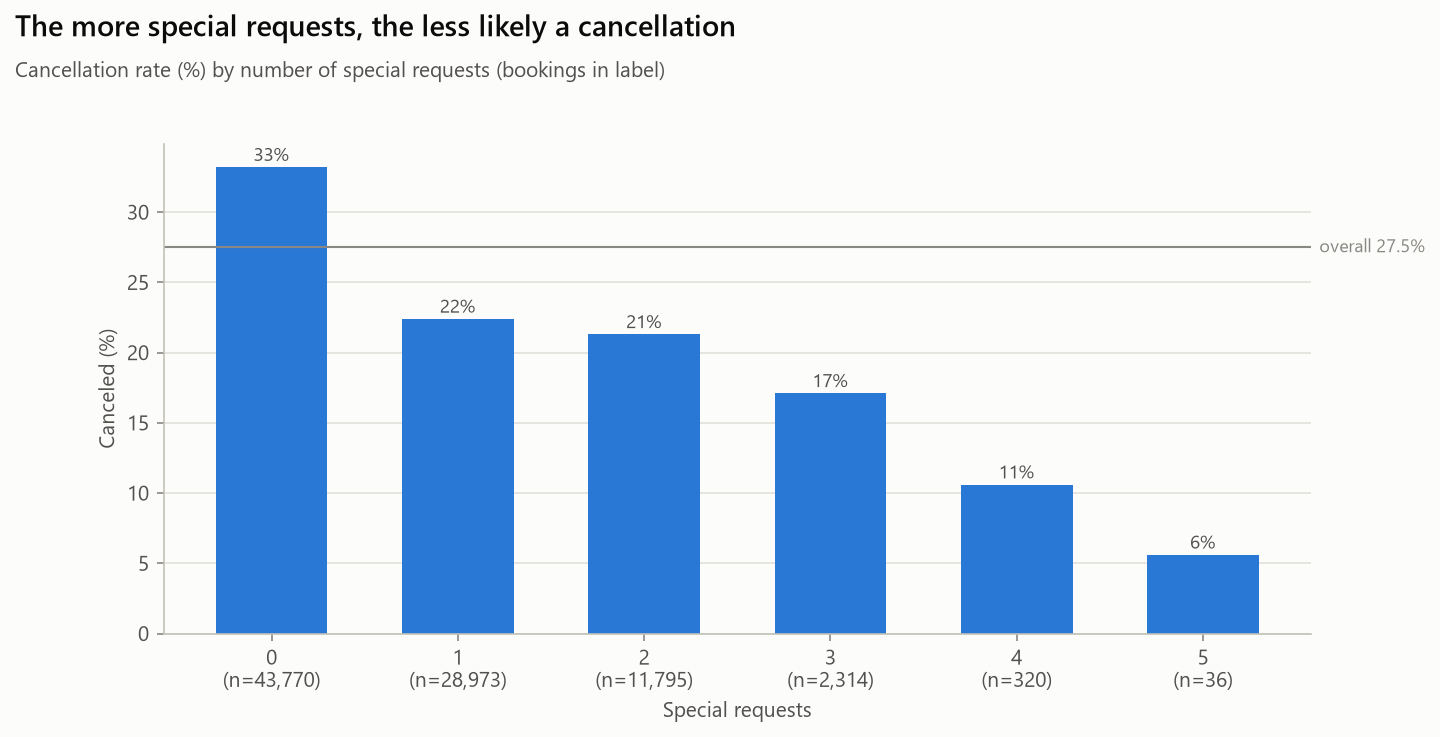

In [31]:
show("10_cancel_by_special_requests")

## 5. Feature selection

Three checks run on the **training rows only** (selection is a form of fitting). They *flag* columns; each final decision is written down in `config.DROPPED_FEATURES` and `docs/decisions.md` section 6. `select_features()` re-validates the final list and fails if leakage or a redundant pair slips through.

In [32]:
from src.features import find_correlated_pairs, find_near_constant, target_purity
from src.pipeline import FeatureGroups, select_features

candidates = FeatureGroups.from_config()
selected, train_rows = select_features(featured, candidates)

13:23:25 | INFO    | src.features       | Leakage check (purity >= 0.99): {'reservation_status': 1.0}


13:23:25 | INFO    | src.features       | Redundant pairs (|r| > 0.90):
               feature_a         feature_b  abs_corr
arrival_date_week_number arrival_month_num     0.995
    stays_in_week_nights      total_nights     0.950


13:23:25 | INFO    | src.features       | Near-constant (>= 98% one value): {'babies': 0.9895, 'previous_cancellations': 0.9808, 'previous_cancel_ratio': 0.9808, 'days_in_waiting_list': 0.9901}


13:23:25 | INFO    | src.pipeline       | Dropped assigned_room_type         Leakage: set at check-in; changed rooms cancel 4.7% vs 31.5%


13:23:25 | INFO    | src.pipeline       | Dropped booking_changes            Leakage risk: snapshot taken at the outcome date


...

13:23:25 | INFO    | src.pipeline       | Dropped arrival_date_month         Redundant: same information as arrival_month_num


13:23:25 | INFO    | src.pipeline       | Dropped arrival_date_year          Does not generalise: future bookings have unseen years


13:23:25 | INFO    | src.pipeline       | Dropped babies                     Near-constant (98.9% zero); covered by has_children and total_guests


13:23:25 | INFO    | src.features       | Selection validated: no leakage, no redundant pairs in 33 features


13:23:25 | INFO    | src.pipeline       | Selected 33 of 40 candidate features


### 5.1 Leakage check - can one column alone predict the target?
Purity = share of rows predicted correctly by the majority class of each value. A useless column scores the baseline (72.5% not canceled); 1.0 means leakage.

In [33]:
pd.Series(
    {c: target_purity(train_rows, c) for c in candidates.categorical + config.LEAKAGE_COLUMNS},
    name="purity",
).round(3).sort_values(ascending=False).to_frame()

,purity
reservation_status,1.000
reservation_status_date,0.739
deposit_type,0.736
country,0.727
agent,0.726
hotel,0.725
assigned_room_type,0.725
reserved_room_type,0.725
distribution_channel,0.725
market_segment,0.725


### 5.2 Redundancy and near-constant checks

In [34]:
candidate_numeric = candidates.numeric + candidates.binary
display(find_correlated_pairs(train_rows, candidate_numeric))
pd.Series(find_near_constant(train_rows, candidate_numeric), name="top_value_share").to_frame()

,feature_a,feature_b,abs_corr
0,arrival_date_week_number,arrival_month_num,0.995
1,stays_in_week_nights,total_nights,0.950


,top_value_share
babies,0.9895
previous_cancellations,0.9808
previous_cancel_ratio,0.9808
days_in_waiting_list,0.9901


13:23:26 | INFO    | src.visualize      | Saved figure 11_correlation_heatmap.png


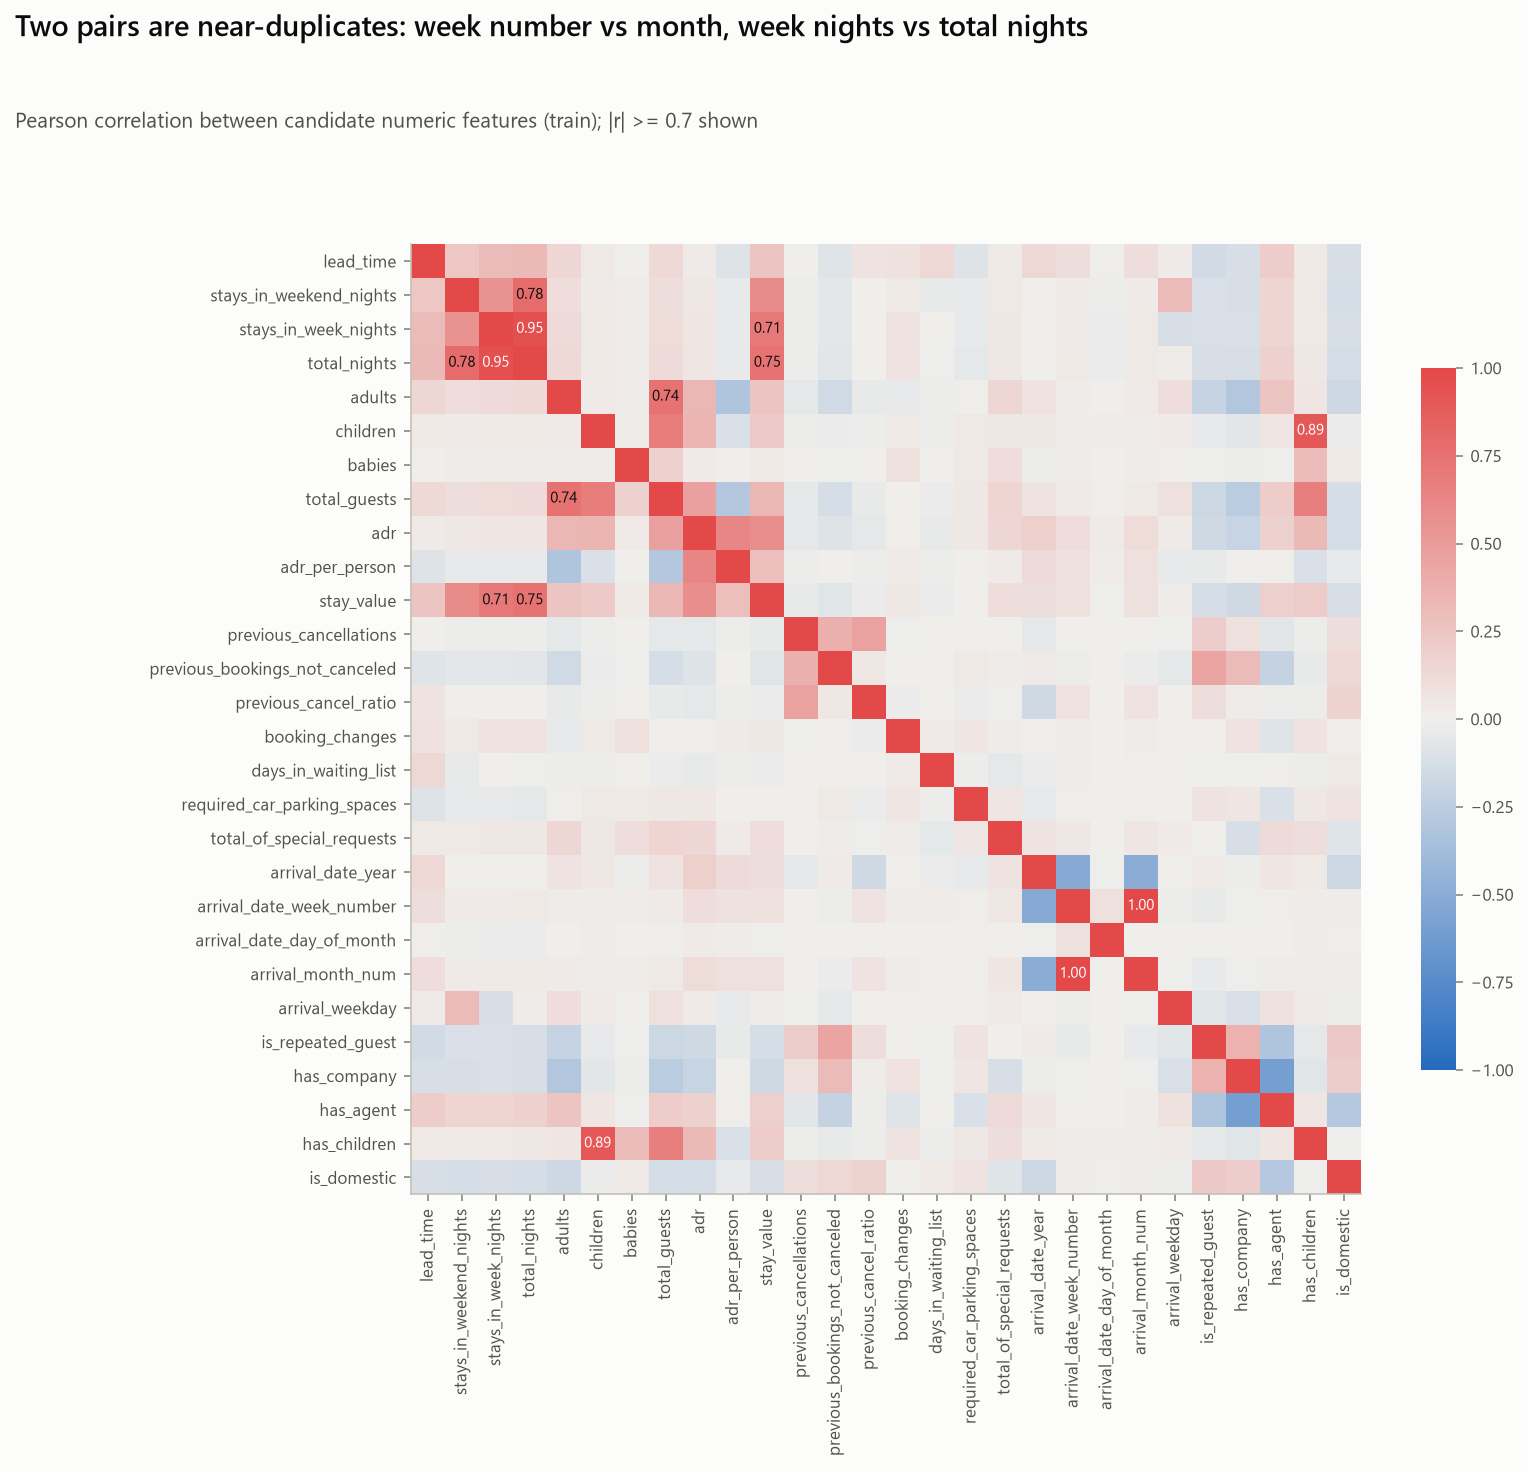

In [35]:
from src.visualize import plot_correlation_heatmap

save_figure(plot_correlation_heatmap(train_rows, candidate_numeric), "11_correlation_heatmap")
show("11_correlation_heatmap")

### 5.3 Decisions
Flagged but **kept**: `days_in_waiting_list` (waitlisted bookings cancel 34.7% vs 27.4%), `previous_cancellations` / `previous_cancel_ratio` (67% cancel when the guest has a cancellation history), `children` (r = 0.894 with `has_children`, under 0.9).

In [36]:
pd.Series(config.DROPPED_FEATURES, name="reason").to_frame()

,reason
assigned_room_type,Leakage: set at check-in; changed rooms cancel...
booking_changes,Leakage risk: snapshot taken at the outcome date
arrival_date_week_number,Redundant: r = 0.995 with arrival_month_num
stays_in_week_nights,Redundant: r = 0.95 with total_nights (= total...
arrival_date_month,Redundant: same information as arrival_month_num
arrival_date_year,Does not generalise: future bookings have unse...
babies,Near-constant (98.9% zero); covered by has_chi...


In [37]:
pd.DataFrame(
    {
        "group": ["numeric"] * len(selected.numeric)
        + ["binary"] * len(selected.binary)
        + ["categorical"] * len(selected.categorical),
        "feature": selected.all,
    }
).groupby("group")["feature"].agg(["count", ", ".join])

,count,join
group,,
binary,5,"is_repeated_guest, has_company, has_agent, has..."
categorical,10,"hotel, meal, market_segment, distribution_chan..."
numeric,18,"lead_time, stays_in_weekend_nights, total_nigh..."


## 6. Encoding + scaling

Split first (stratified 80/20), then fit the `ColumnTransformer` on the **training rows only**:

- skewed numeric -> `log1p` -> `StandardScaler` (log only where it at least halves the skew)
- other numeric -> `StandardScaler`
- binary flags -> unchanged
- categorical -> `OneHotEncoder`, categories under 1% of training rows -> `infrequent`

In [38]:
from src.pipeline import fit_preprocessing, prepare_new_bookings, save_artifacts, save_model_ready

result = fit_preprocessing(featured, selected, adr_cap, dropped=config.DROPPED_FEATURES)
result.preprocessor

13:23:26 | INFO    | src.pipeline       | Split: 69,766 train / 17,442 test rows (stratified, cancel rate 27.5% / 27.5%)


13:23:26 | INFO    | src.pipeline       | log1p applied to 5 columns: ['stays_in_weekend_nights', 'total_nights', 'previous_cancellations', 'previous_bookings_not_canceled', 'total_of_special_requests']


13:23:26 | INFO    | src.pipeline       | Preprocessor fitted on train: 33 input columns -> 86 model features


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

In [39]:
meta = result.metadata
rates = meta["cancel_rate_pct"]
rows = meta["rows"]
pd.Series(
    {
        "train rows": rows["train"],
        "test rows": rows["test"],
        "cancel rate train / test (%)": f"{rates['train']} / {rates['test']}",
        "input features": len(meta["input_features"]),
        "model features after encoding": len(meta["output_features"]),
        "log1p columns": ", ".join(meta["log_features"]),
        "ADR cap reused for new data": meta["adr_cap"],
    },
    name="value",
).to_frame()

,value
train rows,69766
test rows,17442
cancel rate train / test (%),27.51 / 27.51
input features,33
model features after encoding,86
log1p columns,"stays_in_weekend_nights, total_nights, previou..."
ADR cap reused for new data,335.0


### 6.1 Proof that the scaler was fitted on train only
Scaled training columns have mean 0 and std 1 exactly; the test set is close but not exact, because it was only *transformed* with the training statistics.

In [40]:
scaled = [c for c in result.train.columns if c.startswith(("num__", "log__"))]
pd.DataFrame(
    {
        "train mean": result.train[scaled].mean(),
        "test mean": result.test[scaled].mean(),
        "train std": result.train[scaled].std(),
        "test std": result.test[scaled].std(),
    }
).round(3).head(8)

,train mean,test mean,train std,test std
log__stays_in_weekend_nights,-0.0,0.004,1.0,0.999
log__total_nights,-0.0,0.003,1.0,1.005
log__previous_cancellations,-0.0,-0.000,1.0,0.975
log__previous_bookings_not_canceled,0.0,0.001,1.0,0.997
log__total_of_special_requests,-0.0,-0.005,1.0,0.997
num__lead_time,0.0,-0.005,1.0,0.997
num__adults,0.0,-0.012,1.0,0.994
num__children,-0.0,-0.010,1.0,0.988


### 6.2 The model-ready training set

In [41]:
result.train.head()

,log__stays_in_weekend_nights,log__total_nights,log__previous_cancellations,log__previous_bookings_not_canceled,log__total_of_special_requests,num__lead_time,num__adults,num__children,num__total_guests,num__adr,num__adr_per_person,num__stay_value,num__previous_cancel_ratio,num__days_in_waiting_list,num__required_car_parking_spaces,num__arrival_date_day_of_month,num__arrival_month_num,num__arrival_weekday,bin__is_repeated_guest,bin__has_company,...,cat__country_IRL,cat__country_ITA,cat__country_NLD,cat__country_PRT,cat__country_USA,cat__country_infrequent_sklearn,cat__agent_0,cat__agent_1,cat__agent_14,cat__agent_240,cat__agent_241,cat__agent_250,cat__agent_28,cat__agent_40,cat__agent_6,cat__agent_7,cat__agent_8,cat__agent_9,cat__agent_infrequent_sklearn,is_canceled
22789,-1.122502,0.418437,5.358372,2.108849,1.486771,3.219226,0.244687,-0.306317,-0.038228,0.688498,0.539798,0.472604,4.367438,-0.074896,-0.300856,1.604247,0.492222,-0.489579,1,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
31498,0.246942,-0.576496,-0.126832,-0.177483,0.594788,-0.546421,0.244687,-0.306317,-0.038228,0.916371,0.747478,-0.236667,-0.122476,-0.074896,3.284647,0.359072,-0.153049,-1.486528,0,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
87136,-1.122502,0.773544,-0.126832,-0.177483,-0.930066,0.673927,-1.735003,-0.306317,-1.463687,0.218052,2.189603,0.528664,-0.122476,-0.074896,-0.300856,1.491049,0.492222,-0.988053,0,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
63888,0.246942,-0.576496,-0.126832,-0.177483,0.594788,0.150921,0.244687,-0.306317,-0.038228,0.392148,0.269708,-0.384024,-0.122476,-0.074896,-0.300856,0.472269,-0.153049,-1.486528,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0
52740,1.048015,-0.016179,5.358372,-0.177483,-0.930066,2.905422,0.244687,-0.306317,-0.038228,-0.847804,-0.860369,-0.561831,8.857352,-0.074896,-0.300856,-0.433312,0.814857,1.005844,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1


In [42]:
save_artifacts(result)
save_model_ready(result)

13:23:26 | INFO    | src.pipeline       | Saved preprocessor.joblib and preprocessing_metadata.json


13:23:29 | INFO    | src.pipeline       | Saved train_processed.csv (69,766 rows x 87 columns)


13:23:30 | INFO    | src.pipeline       | Saved test_processed.csv (17,442 rows x 87 columns)


### 6.3 Reusing the saved pipeline on new raw data
This is what the web app does with an uploaded CSV: clean with the *training* ADR cap, engineer features and `transform` with the fitted preprocessor - nothing is re-fitted.

In [43]:
new_raw = df.sample(500, random_state=config.RANDOM_STATE)
model_ready, new_cleaning = prepare_new_bookings(new_raw, result.preprocessor, result.metadata)
print(
    f"{len(new_raw)} raw rows -> {len(model_ready)} model-ready rows x "
    f"{model_ready.shape[1]} columns"
)
new_cleaning.report[["rows_removed", "values_changed"]]

13:23:30 | INFO    | src.cleaning       | -> Drop zero-guest bookings


13:23:30 | INFO    | src.cleaning       | Zero-guest bookings dropped: 1


13:23:30 | INFO    | src.cleaning       | -> Drop negative ADR


13:23:30 | INFO    | src.cleaning       | Negative-ADR rows dropped: 0


13:23:30 | INFO    | src.cleaning       | -> Drop implausible counts


...

13:23:30 | INFO    | src.cleaning       | Cleaning done: 500 -> 492 rows (8 removed, 1.6%)


13:23:30 | INFO    | src.features       | Engineered 10 features: ['total_nights', 'total_guests', 'has_children', 'adr_per_person', 'stay_value', 'arrival_month_num', 'arrival_weekday', 'arrival_season', 'is_domestic', 'previous_cancel_ratio']


13:23:30 | INFO    | src.features       | Shape after feature engineering: 492 rows x 43 columns


500 raw rows -> 492 model-ready rows x 87 columns


,rows_removed,values_changed
step,,
Drop zero-guest bookings,1,0
Drop negative ADR,0,0
Drop implausible counts,0,0
Drop exact duplicates,7,0
company -> has_company flag,0,0
Fill agent + has_agent flag,0,51
Fill country 'Unknown',0,2
Fill children 0,0,0
meal Undefined -> SC,0,8


## 7. Summary

In [44]:
n_out = len(meta["output_features"])
split = f"{rows['train']:,} train / {rows['test']:,} test"
pd.DataFrame(
    {
        "raw": {
            "rows": f"{len(df):,}",
            "missing cells": f"{int(df.isna().sum().sum()):,}",
            "ADR max": f"{df['adr'].max():,.0f}",
            "cancellation rate": f"{df[config.TARGET].mean():.1%}",
            "columns / features": f"{df.shape[1]} columns",
        },
        "model-ready": {
            "rows": f"{len(clean_df):,} ({split})",
            "missing cells": f"{int(clean_df.isna().sum().sum()):,}",
            "ADR max": f"{adr_cap:,.0f} (capped)",
            "cancellation rate": f"{clean_df[config.TARGET].mean():.1%}",
            "columns / features": f"{len(selected.all)} inputs -> {n_out} features",
        },
    }
)

,raw,model-ready
rows,"119,390","87,208 (69,766 train / 17,442 test)"
missing cells,"129,425",0
ADR max,"5,400",335 (capped)
cancellation rate,37.0%,27.5%
columns / features,32 columns,33 inputs -> 86 features


**Outputs**

- `data/processed/hotel_bookings_clean.csv` - cleaned data (for EDA)
- `data/processed/train_processed.csv`, `test_processed.csv` - model-ready matrices + target
- `models/preprocessor.joblib` + `models/preprocessing_metadata.json` - fitted pipeline
- `reports/figures/` - 11 figures
- `docs/decisions.md` - every preprocessing decision, with reasons and alternatives

The same pipeline runs from the terminal with `python main.py`.